# Probabilistic FDM — Poisson方程式 (Matérnカーネル)

PDE: $-u''(x) = f(x) = \sin(2\pi x)$, $\quad u(0)=u(18)=0$

真の解: $u(x) = \frac{1}{(2\pi)^2}\sin(2\pi x)$

観測モデル: $y = H u + \varepsilon$, $\quad H = -\Delta_h$

観測ノイズ:
\[
\varepsilon \sim \mathcal{N}(0,\, C h^{2\tau} I_{M,N}).
\]

この版では

- $\tau=2$ を固定
- $\sigma_f$ は標準FDM解の RMS から固定
- $C$ は target-grid の標準FDM解 $u_h$ に $2h$ stencil を適用した coarsening defect から推定
- $\ell$ のみ log marginal likelihood でグリッドサーチ

とする。追加の $h/2$ solve は不要。


In [5]:
using Plots
using LinearAlgebra
using SpecialFunctions
using Printf
using Statistics

In [6]:
function solve_fdm(dt)
    x_all = collect(0.0:dt:18.0)
    x_int = x_all[2:end-1]
    n_int = length(x_int)
    A = SymTridiagonal(fill(2.0/dt^2, n_int), fill(-1.0/dt^2, n_int-1))
    f_vec = f_func.(x_int)
    u_int = ldiv!(factorize(A), copy(f_vec))
    return x_all, vcat(0.0, u_int, 0.0)
end

dt = 0.4
x_fdm, u_fdm = solve_fdm(dt)
err = maximum(abs.(u_fdm .- u_exact.(x_fdm)))
println("h=$(dt):  max|u_fdm - u_exact| = $(round(err, sigdigits=4))")



σf_rms  = sqrt(mean(u_fdm.^2))
σf_max = maximum(abs.(u_fdm))

println(σf_rms)
println(σf_max)

# --------------------------------------------------------
# C の coarsening-based calibration
#
# truncation error:
#     D_h u - f = c(x) h^p + higher-order terms
#
# target-grid FDM solution u_h を一段粗い 2h stencil で検査すると
#     D_{2h} u_h - f ≈ (2^p - 1) c(x) h^p
#
# よって
#     c_hat(x) = [D_{2h} u_h - f] / [(2^p - 1) h^p]
#     C_hat    = mean(c_hat(x)^2)
#
# 注意:
# [0,18] と h=0.4 のように interval 数が奇数でも使えるよう、
# 完全な 2h-grid は作らず、u_h 上で ±2 index が存在する
# every-other interior point のみを使用する。
# --------------------------------------------------------
function estimate_C_coarsening(dt; p=2)
    x_h, u_h = solve_fdm(dt)
    n = length(x_h)

    # Julia index i corresponds to x_h[i].
    # Use centers i = 3,5,7,... such that i-2 and i+2 both exist.
    idx = collect(3:2:(n-2))
    if isempty(idx)
        error("Grid is too coarse to estimate C using a 2h stencil.")
    end

    h2 = 2dt
    defect = similar(Float64.(idx))

    for (k, i) in enumerate(idx)
        D2h_u = (-u_h[i-2] + 2u_h[i] - u_h[i+2]) / h2^2
        defect[k] = D2h_u - f_func(x_h[i])
    end

    c_hat = defect ./ ((2.0^p - 1.0) * dt^p)
    C_hat = mean(c_hat .^ 2)

    return C_hat, x_h[idx], c_hat, defect
end


h=0.4:  max|u_fdm - u_exact| = 0.01797
0.030928558807569867
0.04205848896953482


estimate_C_coarsening (generic function with 1 method)

## 1. Matérnカーネル

In [7]:
function matern_kernel(x1, x2; ν=1.5, ℓ=1.0, σf=1.0)
    r = abs(x1 - x2)
    if r == 0
        return σf^2
    end
    z = sqrt(2ν) * r / ℓ
    if ν == 0.5
        return σf^2 * exp(-z)
    elseif ν == 1.5
        return σf^2 * (1 + z) * exp(-z)
    elseif ν == 2.5
        return σf^2 * (1 + z + z^2/3) * exp(-z)
    else
        return σf^2 * (2^(1-ν) / gamma(ν)) * z^ν * besselk(ν, z)
    end
end

function kernel_matrix_matern(X1, X2; ν=1.5, ℓ=1.0, σf=1.0)
    [matern_kernel(x1, x2; ν=ν, ℓ=ℓ, σf=σf) for x1 in X1, x2 in X2]
end

kernel_matrix_matern (generic function with 1 method)

## 2. 問題設定・観測行列 H・log周辺尤度

In [8]:
# --------------------------------------------------------
# 問題設定: -u'' = f, u(0)=u(1)=0
# f(x) = sin(2πx), u_exact(x) = sin(2πx)/(2π)^2
# --------------------------------------------------------
u_exact(x) = sin(2π * x) / (2π)^2
f_func(x)  = sin(2π * x)

# --------------------------------------------------------
# 観測行列 H = -Δ_h (負の有限差分ラプラシアン)
# 行順: [bdry_0, int_1, ..., int_{N-1}, bdry_N]
# 内点行: (-u_{i-1} + 2u_i - u_{i+1}) / h^2  = -Δ_h u_i ≈ -u''_i = f_i
# → Hu = y = (0, f(x_1), ..., f(x_{N-1}), 0) と直接対応
# --------------------------------------------------------
function observation_matrix(n_total, dt)
    n_int = n_total - 2
    H = zeros(n_total, n_total)
    H[1, 1]     = 1.0
    H[end, end] = 1.0
    for i in 1:n_int
        H[i+1, i]   = -1.0 / dt^2   # -Δ_h
        H[i+1, i+1] =  2.0 / dt^2
        H[i+1, i+2] = -1.0 / dt^2
    end
    return H
end

# 観測ベクトル: y = (u(0), f(x_1), ..., f(x_{N-1}), u(1))
make_y_train(x_all) = vcat(0.0, f_func.(x_all[2:end-1]), 0.0)

# --------------------------------------------------------
# log周辺尤度: 観測ノイズ Σ = C * h^{2τ} * diag(0,1,...,1,0)
# --------------------------------------------------------
function log_marginal_matern(
    X_train, y; H, dt, ν, ℓ, σf, C, τ, jitter=1e-10
)
    n_total   = length(X_train)
    noise_var = C * dt^(2τ)
    Σ_diag    = vcat([0.0], fill(noise_var, n_total - 2), [0.0])
    Σ         = Diagonal(Σ_diag)

    K     = kernel_matrix_matern(X_train, X_train; ν=ν, ℓ=ℓ, σf=σf)
    K_obs = H * K * H' + Σ #+ jitter * I

    L       = cholesky(Hermitian(K_obs)).L
    α       = L' \ (L \ y)
    logdetK = 2sum(log.(diag(L)))

    return -0.5 * (y' * α) - 0.5 * logdetK - 0.5 * length(y) * log(2π)
end

log_marginal_matern (generic function with 1 method)

## 3. Hyperparameter selection by grid search

We remove the numerical-analysis-based selection of \(C\) and \(\ell\).

The prior amplitude is fixed from the deterministic FDM solution by

\[
\sigma_f=\sqrt{\frac1N\sum_i u_h(x_i)^2},
\]

while \(\ell\) and \(C\) are selected jointly by maximizing the exact Gaussian log marginal likelihood over a candidate grid.


In [16]:
# ============================================================
# Hyperparameter grid search
#
# sigma_f : fixed from FDM RMS
# ell, C  : selected by log marginal likelihood
# ============================================================

ν_fixed = 1.5
τ_fixed = 2

dt_list = [0.4]

# Direct grids
ell_grid = [0.0005, 0.05, 0.1, 0.2, 0.4, 0.5, 1.0, 2.0, 5.0]

C_grid = [
    1e-10,
    1e-6,
    1e-4,
    1e-2,
    1e-1,
    1.0,
    10.0,
    1e2,
    1e3,
    1e4,
    1e5,
    1e6
]

best_params = Dict()
lml_tables = Dict()

for dt in dt_list

    x_train = collect(0.0:dt:18.0)
    n_train = length(x_train)

    H       = observation_matrix(n_train, dt)
    y_train = make_y_train(x_train)

    # --------------------------------------------------------
    # sigma_f fixed from deterministic FDM RMS
    # --------------------------------------------------------
    _, u_fdm = solve_fdm(dt)

    sigma_f =
        sqrt(mean(u_fdm.^2))

    # --------------------------------------------------------
    # Joint grid search over ell and C
    # --------------------------------------------------------
    lml_table =
        fill(
            -Inf,
            length(ell_grid),
            length(C_grid)
        )

    for (i, ell) in enumerate(ell_grid)
        for (j, C) in enumerate(C_grid)

            try
                lml_table[i,j] =
                    log_marginal_matern(
                        x_train,
                        y_train;
                        H=H,
                        dt=dt,
                        ν=ν_fixed,
                        ℓ=ell,
                        σf=sigma_f,
                        C=C,
                        τ=τ_fixed
                    )

            catch err
                @warn "LML failed" dt ell C exception=(err, catch_backtrace())
                lml_table[i,j] = -Inf
            end
        end
    end

    best_idx =
        argmax(lml_table)

    best_i, best_j =
        Tuple(best_idx)

    best_ell =
        ell_grid[best_i]

    best_C =
        C_grid[best_j]

    best_lml =
        lml_table[best_i,best_j]

    best_params[dt] =
        (
            best_ell,
            sigma_f,
            best_C
        )

    lml_tables[dt] =
        lml_table

    println("==============================================")
    println("dt = $(dt)")
    println("==============================================")

    @printf("sigma_f = %.6g  [FDM RMS]\n", sigma_f)
    @printf("best ell = %.6g\n", best_ell)
    @printf("best C   = %.6g\n", best_C)
    @printf("best LML = %.6g\n", best_lml)
end


dt = 0.4
sigma_f = 0.0309286  [FDM RMS]
best ell = 0.0005
best C   = 1e-10
best LML = 10.188


In [17]:
# ============================================================
# Marginal likelihood table
# ============================================================

for dt in dt_list

    lml_table =
        lml_tables[dt]

    println()
    println("=== Log marginal likelihood table: dt=$(dt) ===")

    @printf("%-10s", "ell \\ C")

    for C in C_grid
        @printf("%13.2e", C)
    end

    println()

    println(
        "-"^(
            10 +
            13*length(C_grid)
        )
    )

    for (i, ell) in enumerate(ell_grid)

        @printf(
            "%-10.3g",
            ell
        )

        for j in eachindex(C_grid)

            val =
                lml_table[i,j]

            if isfinite(val)
                @printf(
                    "%13.2f",
                    val
                )
            else
                @printf(
                    "%13s",
                    "-Inf"
                )
            end
        end

        println()
    end

    best_ell,
    sigma_f,
    best_C =
        best_params[dt]

    best_i =
        findfirst(==(best_ell), ell_grid)

    best_j =
        findfirst(==(best_C), C_grid)

    println()

    @printf(
        "Best: ell=%.6g, C=%.6g, sigma_f=%.6g, LML=%.6g\n",
        best_ell,
        best_C,
        sigma_f,
        lml_table[best_i,best_j]
    )
end



=== Log marginal likelihood table: dt=0.4 ===
ell \ C        1.00e-10     1.00e-06     1.00e-04     1.00e-02     1.00e-01     1.00e+00     1.00e+01     1.00e+02     1.00e+03     1.00e+04     1.00e+05     1.00e+06
----------------------------------------------------------------------------------------------------------------------------------------------------------------------
0.0005            10.19        10.17         9.40         4.27        -2.31       -14.10       -31.98       -61.46      -107.28      -157.38      -207.98      -258.63
0.05              10.19        10.17         9.40         4.27        -2.31       -14.10       -31.98       -61.46      -107.28      -157.38      -207.98      -258.63
0.1                9.90         9.88         9.11         4.01        -2.55       -14.28       -32.04       -61.45      -107.28      -157.38      -207.98      -258.63
0.2                4.09         4.08         3.42        -1.32        -7.47       -18.26       -33.29       -61.30    

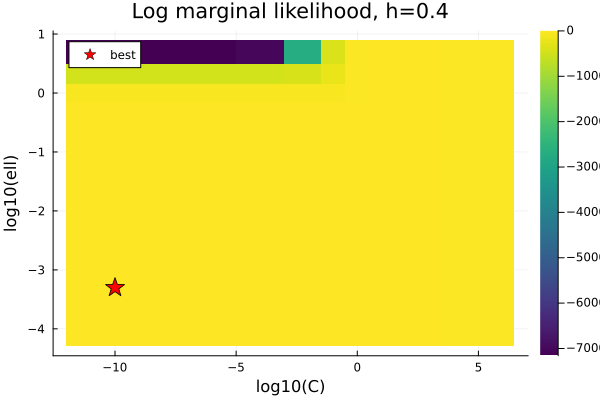

In [19]:
# ============================================================
# LML heatmap
# ============================================================

for dt in dt_list

    lml_table =
        lml_tables[dt]

    finite_vals =
        lml_table[
            isfinite.(lml_table)
        ]

    floor_val =
        isempty(finite_vals) ?
        -1e6 :
        minimum(finite_vals)

    Z =
        copy(lml_table)

    Z[.!isfinite.(Z)] .=
        floor_val

    best_ell,
    sigma_f,
    best_C =
        best_params[dt]

    p_lml = heatmap(
        log10.(C_grid),
        log10.(ell_grid),
        Z;
        xlabel="log10(C)",
        ylabel="log10(ell)",
        title="Log marginal likelihood, h=$(dt)",
        color=:viridis
    )

    scatter!(
        p_lml,
        [log10(best_C)],
        [log10(best_ell)];
        marker=:star5,
        markersize=10,
        color=:red,
        label="best"
    )

    display(p_lml)
end


## 4. Posterior using the grid-search optimum

The posterior is evaluated on a fine test grid, while the FDM solution remains on the coarse training grid.


In [20]:
function run_pfdm(dt; ν, ℓ, σf, C, τ, n_test=1801)
    # --------------------------------------------------------
    # Training grid
    # --------------------------------------------------------
    x_train = collect(0.0:dt:18.0)
    n_train = length(x_train)

    H       = observation_matrix(n_train, dt)
    y_train = make_y_train(x_train)

    noise_var = C * dt^(2τ)
    Σ_diag = vcat(
        [0.0],
        fill(noise_var, n_train - 2),
        [0.0]
    )
    Σ = Diagonal(Σ_diag)

    K_train = kernel_matrix_matern(
        x_train, x_train;
        ν=ν, ℓ=ℓ, σf=σf
    )

    K_obs = Hermitian(
        H * K_train * H' +
        Σ +
        1e-10 * I
    )

    K_chol = cholesky(K_obs)

    # --------------------------------------------------------
    # Fine test grid
    # --------------------------------------------------------
    X_test = collect(
        range(0.0, 18.0, length=n_test)
    )

    K_test_train = kernel_matrix_matern(
        X_test, x_train;
        ν=ν, ℓ=ℓ, σf=σf
    )

    # Cross covariance with observations
    Ks = K_test_train * H'

    # Posterior mean
    μ_post = Ks * (K_chol \ y_train)

    # Posterior variance:
    # k(x*,x*) = σf^2 for stationary Matérn kernel
    W = K_chol.L \ Ks'

    var_post =
        σf^2 .-
        vec(sum(W.^2, dims=1))

    std_post =
        sqrt.(max.(var_post, 0.0))

    u_true =
        u_exact.(X_test)

    return X_test, μ_post, std_post, u_true
end

run_pfdm (generic function with 1 method)

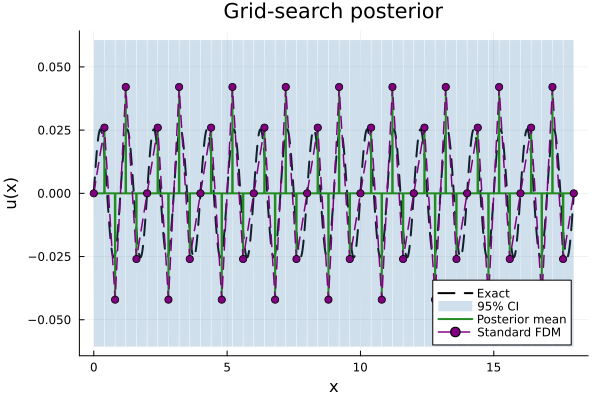

Fine test-grid posterior
h              = 0.4
ell            = 0.0005
C              = 1e-10
sigma_f        = 0.0309286
RMSE           = 0.0178067
Linf           = 0.0253303
coverage       = 0.980
mean 95% half-width = 0.059074


In [21]:
# ============================================================
# Fine-test posterior with the selected ell and C
# ============================================================

for dt in dt_list

    best_ell,
    sigma_f,
    best_C =
        best_params[dt]

    X_test,
    mu,
    std,
    u_true_vals =
        run_pfdm(
            dt;
            ν=ν_fixed,
            ℓ=best_ell,
            σf=sigma_f,
            C=best_C,
            τ=τ_fixed,
            n_test=1801
        )

    abs_err =
        abs.(
            mu .-
            u_true_vals
        )

    rmse =
        sqrt(
            mean(
                (
                    mu .-
                    u_true_vals
                ).^2
            )
        )

    linf =
        maximum(abs_err)

    coverage =
        mean(
            abs_err .<=
            1.96 .* std
        )

    mean_halfwidth =
        mean(
            1.96 .* std
        )

    println("==============================================")
    println("Fine test-grid posterior")
    println("==============================================")

    @printf("h              = %.6g\n", dt)
    @printf("ell            = %.6g\n", best_ell)
    @printf("C              = %.6g\n", best_C)
    @printf("sigma_f        = %.6g\n", sigma_f)
    @printf("RMSE           = %.6g\n", rmse)
    @printf("Linf           = %.6g\n", linf)
    @printf("coverage       = %.3f\n", coverage)
    @printf("mean 95%% half-width = %.6g\n", mean_halfwidth)

    x_fdm,
    u_fdm =
        solve_fdm(dt)

    p = plot(
        X_test,
        u_true_vals;
        label="Exact",
        lw=2,
        ls=:dash,
        color=:black,
        xlabel="x",
        ylabel="u(x)",
        title="Grid-search posterior"
    )

    plot!(
        p,
        X_test,
        mu .+
        1.96 .* std;
        fillrange=
            mu .-
            1.96 .* std,
        fillalpha=0.25,
        linealpha=0,
        label="95% CI",
        color=:steelblue
    )

    plot!(
        p,
        X_test,
        mu;
        label="Posterior mean",
        lw=2,
        color=:forestgreen
    )

    plot!(
        p,
        x_fdm,
        u_fdm;
        label="Standard FDM",
        lw=1.5,
        ls=:dash,
        marker=:circle,
        markersize=4,
        color=:purple
    )

    display(p)
end
